# Bonds: yield, accrual, optionality and curve risk

Family 24. Clean and dirty prices are per 100 outstanding principal. Yield
duration describes promised cash flows; effective callable-bond risk requires
repricing the exercise option under each perturbed curve.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(2400)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Price/yield curvature and local duration

A duration-only approximation is local. Adding convexity improves a small
parallel yield change but does not capture every curve or optionality change.

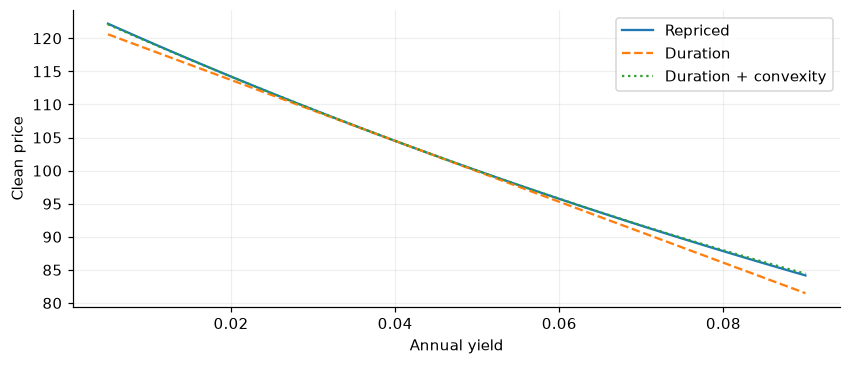

,Clean,Dirty,Accrued,Yield,Duration,Convexity,DV01
0,104.307911,104.307911,0.0,0.040403,4.411463,22.932966,0.046015


In [2]:
from convexity.math import fixed_income as fi, rates as ra
schedule=ct.schedule('2025-01-01','2031-01-01')
bond=fi.fixed_bond(schedule,.05)
base=fi.bond_analytics(bond,discount)
yields=np.linspace(.005,.09,60)
exact=np.array([fi.price_from_yield(bond,y,ref) for y in yields])
dy=yields-base.yield_to_maturity
linear=base.clean-base.dirty*base.duration*dy
quadratic=linear+.5*base.dirty*base.convexity*dy**2
plt.plot(yields,exact,label='Repriced');plt.plot(yields,linear,'--',label='Duration');plt.plot(yields,quadratic,':',label='Duration + convexity')
plt.xlabel('Annual yield');plt.ylabel('Clean price');plt.legend();plt.show()
display(pd.DataFrame([{'Clean':base.clean,'Dirty':base.dirty,'Accrued':base.accrued,'Yield':base.yield_to_maturity,'Duration':base.duration,'Convexity':base.convexity,'DV01':base.dv01}]))

## Accrual and amortization

Coupon dates reset accrued interest. An amortizing bond reduces its outstanding
principal, which changes both cash flows and the meaning of a per-100 quote.

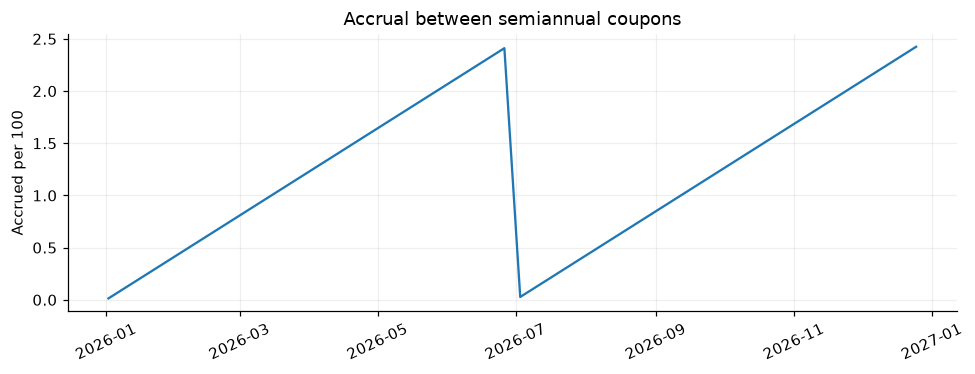

,Date,Amortizing cash flow
0,2027-01-01,5.000000
1,2027-01-01,30.000000
2,2028-01-01,3.500000
3,2028-01-01,30.000000
4,2029-01-01,2.005479
5,2029-01-01,40.000000


In [3]:
dates=pd.date_range('2026-01-02','2026-12-30',freq='7D')
accrual=[fi.bond_analytics(bond,discount,settlement_date=d.date(),compute_yield=False).accrued for d in dates]
plt.plot(dates,accrual);plt.ylabel('Accrued per 100');plt.title('Accrual between semiannual coupons');plt.xticks(rotation=25);plt.tight_layout();plt.show()
amort=fi.amortizing_bond(ct.schedule(ref,'2029-01-01',months=12),[100,70,40],.05)
display(pd.DataFrame([(ct.to_date(cf.date).isoformat(),cf.amount) for cf in fi.cashflows(amort,ref)],columns=['Date','Amortizing cash flow']))

## Callable bonds must use an exercise engine

The issuer's call option reduces bond value. For key-rate sensitivity, the
engine factory rebuilds the curve-fitted rate model for every bumped curve.

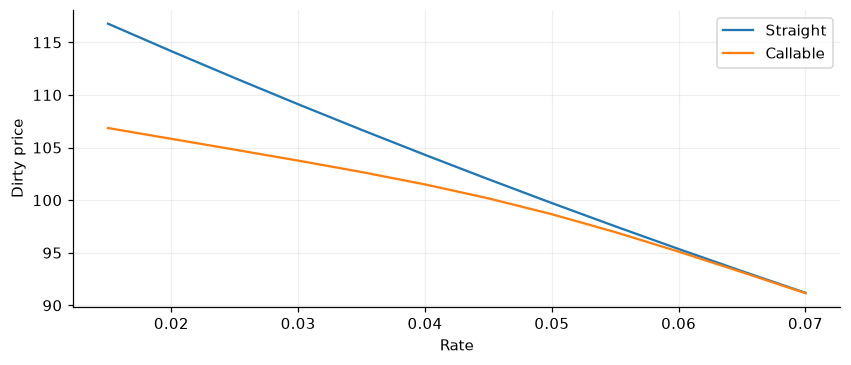

,Key date,Straight KRD,Callable effective KRD
0,2026-01-01,0.028741,0.029538
1,2028-01-01,0.250725,1.579718
2,2031-01-01,4.221115,0.816668


In [4]:
callable_bond=fi.callable_bond(schedule,.05,[('2028-01-01',100,'call')])
def engine(curve):
    return fi.callable_bond_engine(curve,mean_reversion=.1,volatility=.01,steps=160)
rows=[]
for rate in np.linspace(.015,.07,12):
    curve=cv.flat_curve(ref,rate)
    rows.append((rate,fi.bond_analytics(bond,curve,compute_yield=False).dirty,
                 fi.bond_analytics(callable_bond,curve,engine=engine(curve),compute_yield=False).dirty))
prices=pd.DataFrame(rows,columns=['Rate','Straight','Callable'])
prices.plot(x='Rate',y=['Straight','Callable']);plt.ylabel('Dirty price');plt.show()
keys=[ref,'2028-01-01','2031-01-01']
display(pd.DataFrame({'Key date':keys,'Straight KRD':fi.key_rate_duration(bond,discount,keys),
 'Callable effective KRD':fi.key_rate_duration(callable_bond,discount,keys,engine_factory=engine)}))

## Carry and roll-down assumptions

Holding the dated forward curve and holding the zero curve fixed by remaining
tenor are different scenarios. The implied-forward roll has zero excess return
by construction, not because it predicts tomorrow's curve.

In [5]:
curve=cv.zero_curve([ref,'2027-01-01','2029-01-01','2031-01-01'],[.02,.03,.05,.06])
zero=fi.zero_coupon('2031-01-01')
rows=[]
for evolution in ['constant_tenor','implied_forward']:
    r=fi.carry_roll_down(zero,curve,'2027-01-01',evolution=evolution)
    rows.append({'Evolution':evolution,**dict(r.items())})
display(pd.DataFrame(rows))

,Evolution,initial_value,horizon_value,reinvested_coupons,carry,roll_down,total_return
0,constant_tenor,74.069645,80.239788,0,2.255757,3.914386e+00,0.083302
1,implied_forward,74.069645,76.325402,0,2.255757,-4.884981e-15,0.030455


## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../financial_mathematics.md) and [QA record](../financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.